In [53]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 13.4 MB/s  0:00:00m0:00:010:01

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [57]:
%pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [61]:
# Install packages
from pathlib import Path
import mne
import numpy as np
from scipy.io import loadmat
import pandas as pd

# Global variables setup
PATH = Path('/Users/emmaabecasis/Downloads/Meditation/data') # make sure this fits
# may have to edit, depending on file format

METADATA_PATH = Path("/Users/emmaabecasis/Downloads/Meditation/meditation_data_info.xlsx")

participants = pd.read_excel(
    METADATA_PATH,
    sheet_name="Sheet1",
    dtype={"participant_id": str, "file_name": str},
)

EEG_CHANNELS = [
"F4", "C4", "P4", "P3",
"C3", "F3", "Pz",
]

In [62]:
# Import files
if PATH.is_dir():
    items = list(PATH.rglob("*"))

    edfs = [p for p in items if p.is_file() and p.suffix.lower() == ".edf"]
    print("EDF files found:", len(edfs))
    data_files = [str(file_path.resolve()) for file_path in edfs]

else:
    raise ValueError(f"Path {PATH} is not a directory. Please check the path and try again.")

event_id = {
    "pre_meditation": 1,
    "meditation": 2,
    "post_meditation": 3,
}

def add_stage_annotations(raw, file_path):
    filename = Path(file_path).name
    matches = participants.loc[
        participants["file_name"] == filename
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one Excel row for {filename}; "
            f"found {len(matches)}."
        )

    row = matches.iloc[0]
    stage_names = list(event_id)

    starts = pd.to_numeric(
        pd.Series([row[f"{stage}_start_s"] for stage in stage_names]),
        errors="raise",
    ).to_numpy(dtype=float)

    ends = pd.to_numeric(
        pd.Series([row[f"{stage}_end_s"] for stage in stage_names]),
        errors="raise",
    ).to_numpy(dtype=float)

    recording_duration = raw.n_times / raw.info["sfreq"]

    if (
        not np.isfinite(starts).all()
        or not np.isfinite(ends).all()
        or np.any(starts < 0)
        or np.any(ends <= starts)
        or np.any(ends > recording_duration)
    ):
        raise ValueError(
            f"Missing, invalid, or out-of-range stage times for {filename}"
        )

    if np.any(starts[1:] < ends[:-1]):
        raise ValueError(
            f"Stages overlap or are out of order for {filename}"
        )

    # Apply to the freshly loaded recording, before manual annotation.
    # Replaces existing annotations.
    raw.set_annotations(
        mne.Annotations(
            onset=starts,
            duration=ends - starts,
            description=stage_names,
        )
    )

    print(f"\nParticipant: {row['participant_id']}")
    for stage, start, end in zip(stage_names, starts, ends):
        print(f"{stage}: {start:g}–{end:g} seconds")

    return raw

EDF files found: 1


In [65]:
def load_edf(file_path):
    data = mne.io.read_raw_edf(file_path, preload=True)

    # Reference to left ear channel
    data.set_eeg_reference(ref_channels="EEG LE-Pz")

    # Standardize channel names
    rename_dict = {}
    for ch_name in data.ch_names:
        if '-Pz' in ch_name:
            rename_dict[ch_name] = ch_name.replace('-Pz', '')
        if ch_name == "Pz":
                  rename_dict[ch_name] = "EEG Pz"
    data.rename_channels(rename_dict)

    data.rename_channels(lambda name: name.removeprefix("EEG "))

    data.set_channel_types({ch: "eeg" for ch in EEG_CHANNELS})
    data.set_channel_types({
    "LE": "misc",
    "Event": "misc",
    "Trigger": "stim",
    })

    raw = data.copy()
    raw = add_stage_annotations(raw, file_path)

    raw.plot(
        scalings="auto",
        n_channels=7,
        duration=60,
        block=True,
    )
    # band pass filter
    raw.filter(l_freq=0.5, h_freq=41)

    # downsample to 256 HA
    raw.resample(sfreq=256)

    return raw

    # set locations of electrodes to match standard 10-20 system
    # montage = mne.channels.make_standard_montage("standard_1020")
    # raw.set_montage(montage, on_missing="raise")

    # visually inspect data - annotate bad time spans and channels
    # press A to enter annotation mode - close window to save annotations
    fig = raw.plot(
         events=events,
         event_id=event_id,
         event_color={1: "red", 2: "green", 3: "blue"},
         scalings="auto", 
         n_channels=7, 
         duration=60,
         block=True
    )

    # band pass filter
    raw.filter(l_freq=0.5, h_freq=41)

    # downsample to 256 HA
    raw.resample(sfreq=256)

    return raw

# Artifact removal
from mne.preprocessing import ICA

def run_ica(raw):
    raw_ica = raw.copy().pick(picks="eeg")
    raw_ica.rename_channels(lambda name: name.removeprefix("EEG "))

    montage = mne.channels.make_standard_montage('standard_1020')
    raw_ica.set_montage(montage, on_missing="ignore")

    filt_raw = raw_ica.copy().filter(l_freq=1.0, h_freq=None).pick(picks="eeg")
    filt_raw.set_montage(raw_ica.get_montage())
    ica = ICA(max_iter="auto", random_state=97)
    ica.fit(filt_raw)
    return ica

# arbitrary epoch rejection criteria used; we can change if this doesn't fit our data
reject_criteria = dict(
    mag=3000e-15,  # 3000 fT
    grad=3000e-13,  # 3000 fT/cm
    eeg=100e-6,  # 100 µV
    eog=200e-6,   # 200 µV
)  

flat_criteria = dict(mag=1e-15, grad=1e-13, eeg=1e-6)  # 1 fT  # 1 fT/cm  # 1 µV

def segment_epochs(raw, epoch_duration=5):
    events, used_event_id = mne.events_from_annotations(
        raw,
        event_id=event_id,
        chunk_duration=epoch_duration,
    )

    if len(events) == 0:
        raise ValueError("No complete epochs fit within the stage annotations.")

    samples_per_epoch = round(epoch_duration * raw.info["sfreq"])

    return mne.Epochs(
        raw,
        events,
        event_id=used_event_id,
        tmin=0,
        tmax=(samples_per_epoch - 1) / raw.info["sfreq"],
        picks="eeg",
        reject={"eeg": 100e-6},
        flat={"eeg": 1e-6},
        baseline=None,
        reject_by_annotation=True,
        preload=True,
    )
def quality_check(epochs, participant_id):
    original_epoch_count = len(epochs.events)
    epochs.drop_bad()
    retained_epoch_count = len(epochs)
    rejected_epoch_count = original_epoch_count - retained_epoch_count
    
    if original_epoch_count:
        rejected_percentage = (100* rejected_epoch_count / original_epoch_count)
    else:
        rejected_percentage = np.nan
    
    print(f"\n{participant_id} quality summary")
    print(f"Original epochs: {original_epoch_count}")
    print(f"Retained epochs: {retained_epoch_count}")
    print(f"Rejected epochs: {rejected_epoch_count}")
    print(f"Rejected percentage: {rejected_percentage:.1f}%")
    
    epochs.plot_drop_log()
    epochs.plot(n_epochs=min(10, len(epochs)), scalings="auto")
    epochs.compute_psd().plot()
 
    return epochs


In [5]:
%pip install mne-qt-browser PySide6


  Using cached pyside6-6.12.0-cp310-abi3-macosx_14_0_universal2.whl.metadata (5.5 kB)
  Using cached pyside6_addons-6.12.0-cp310-abi3-macosx_14_0_universal2.whl.metadata (4.2 kB)
  Using cached pyside6_webengine-6.12.0.140-cp310-abi3-macosx_14_0_universal2.whl.metadata (3.5 kB)
Using cached pyside6-6.12.0-cp310-abi3-macosx_14_0_universal2.whl (577 kB)
Using cached pyside6_addons-6.12.0-cp310-abi3-macosx_14_0_universal2.whl (90.5 MB)
Using cached pyside6_webengine-6.12.0.140-cp310-abi3-macosx_14_0_universal2.whl (249.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [PySide6]m2/3 [PySide6]WebEngine]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/Users/emmaabecasis/Downloads/Meditation/data/soefae 11_raw.edf
Extracting EDF parameters from /Users/emmaabecasis/Downloads/Meditation/data/soefae 11_raw.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 202199  =      0.000 ...   673.997 secs...
EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.

Participant: P01
pre_meditation: 0–148.25 seconds
meditation: 148.25–435.11 seconds
post_meditation: 435.11–557.15 seconds
Channels marked as bad:
none
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz
- Upper transition bandwidth: 1

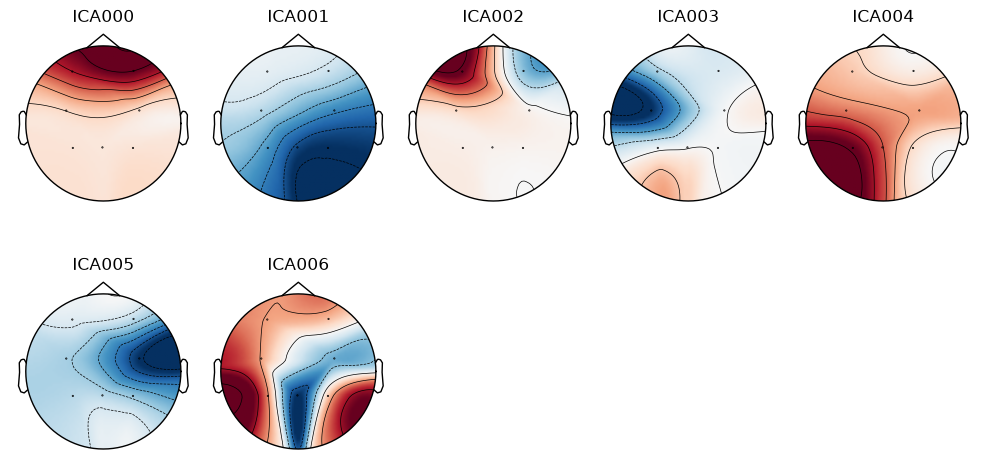

Excluded components: []
Applying ICA to Raw instance
    Transforming to ICA space (7 components)
    Zeroing out 0 ICA components
    Projecting back using 7 PCA components
Used Annotations descriptions: ['meditation', 'post_meditation', 'pre_meditation']
Not setting metadata
110 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 110 events and 1280 original time points ...
    Rejecting  epoch based on EEG : ['F4', 'C4', 'P4', 'P3', 'C3', 'F3', 'Pz']
    Rejecting  epoch based on EEG : ['F4', 'C4', 'P4', 'P3', 'C3', 'F3', 'Pz']
    Rejecting  epoch based on EEG : ['F4', 'C4', 'P4', 'P3', 'C3', 'F3', 'Pz']
    Rejecting  epoch based on EEG : ['F4', 'C3', 'F3']
    Rejecting  epoch based on EEG : ['F4', 'C4', 'C3', 'F3']
    Rejecting  epoch based on EEG : ['F4', 'C3', 'F3']
    Rejecting  epoch based on EEG : ['F4', 'C3', 'F3']
    Rejecting  epoch based on EEG : ['F4', 'C4', 'P3', 'C3', 'F3']
    Rejecting  epoch based 

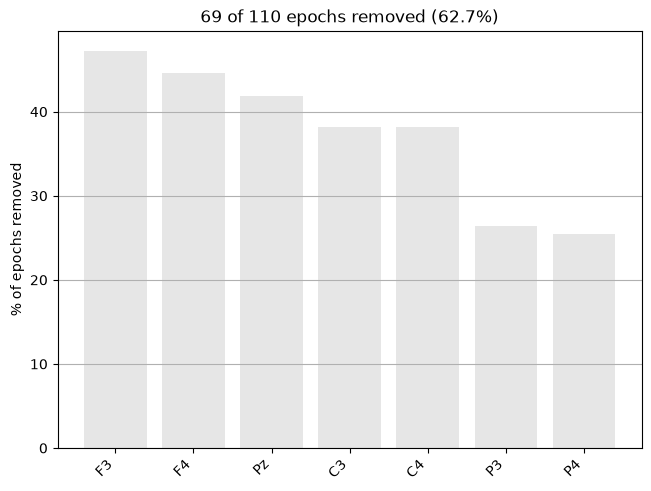

    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


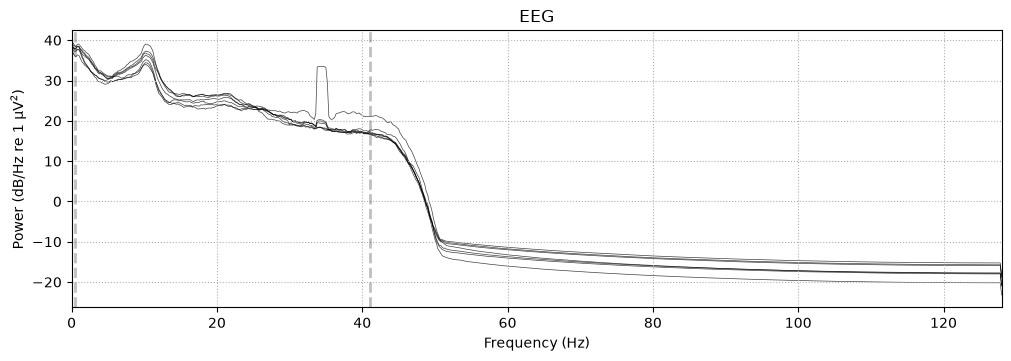

Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none


In [ ]:
# install mne-qt-browser
mne.viz.set_browser_backend("qt")

icas = []
raws = []
epochs_list = []

for file in data_files:
    print(file)

    raw = load_edf(file)
    ica_obj = run_ica(raw)

    # Click artifact components to mark them for exclusion.
    # Close the window when finished; processing then continues.
    ica_obj.plot_sources(
        raw,
        show_scrollbars=False,
        block=True,
    )

    ica_obj.plot_components()

    print(f"Excluded components: {ica_obj.exclude}")

    # Apply ICA to a copy, preserving the original recording.
    cleaned_raw = ica_obj.apply(raw.copy())

    icas.append(ica_obj)
    raws.append(cleaned_raw)

    epochs = segment_epochs(cleaned_raw)
    quality_check(epochs, file)
    epochs_list.append(epochs)